# Part 2: CNN using PyTorch with GradCAM

## CS 437: Deep Learning — Spring 2026

---

### 🎯 Assignment Overview

In this part, you will:

1. **Design** a CNN with less than 1 million parameters using PyTorch
2. **Train** the model on CIFAR-10
3. **Visualize** predictions and confusion matrices
4. **Use** GradCAM (provided) for visual explanations
5. **Implement** visualization functions to analyze attention regions at different layers

**Dataset**: CIFAR-10 (60,000 color 32×32 images, 10 classes)

---

### 📋 Grading Rubric

| Section | Points | Description |
|---------|--------|-------------|
| Part 2: CNN Architecture (<1M params) | 20 | Efficient architecture design |
| Part 3: Training Implementation | 15 | Correct training loop and evaluation |
| Part 4: Confusion Matrix & Predictions | 15 | Visualization of model performance |
| Part 6: GradCAM Visualizations | 30 | Single-image and multi-layer visualizations |
| Part 7: Analysis Questions | 20 | Written analysis and critical thinking |
| **Total** | **100** | |

---

### ⚠️ Instructions

- Complete all cells marked with `# TODO`
- Your CNN must have **less than 1 million parameters**
- Do NOT modify the hyperparameters or random seeds
- GradCAM class is provided — focus on using it effectively for visualizations
- Run all cells in order
- Submit the completed `.ipynb` file with all outputs

## Part 0: Environment Setup & Imports

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as transforms

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from tqdm.auto import tqdm
import time
import cv2

# Set seeds for reproducibility (DO NOT MODIFY)
torch.manual_seed(42)
np.random.seed(42)

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [2]:
# Configuration (DO NOT MODIFY)
CLASS_NAMES = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

BATCH_SIZE = 128
LEARNING_RATE = 1e-3
NUM_EPOCHS = 15
NUM_CLASSES = 10

## Part 1: Data Loading

In [3]:
# Data loading (provided)
transform_train = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))
])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))
])

train_dataset = torchvision.datasets.CIFAR10(
    root='./data', train=True, download=True, transform=transform_train
)
test_dataset = torchvision.datasets.CIFAR10(
    root='./data', train=False, download=True, transform=transform_test
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"Training samples: {len(train_dataset)}")
print(f"Test samples: {len(test_dataset)}")
print(f"Image shape: {train_dataset[0][0].shape}")

Training samples: 50000
Test samples: 10000
Image shape: torch.Size([3, 32, 32])


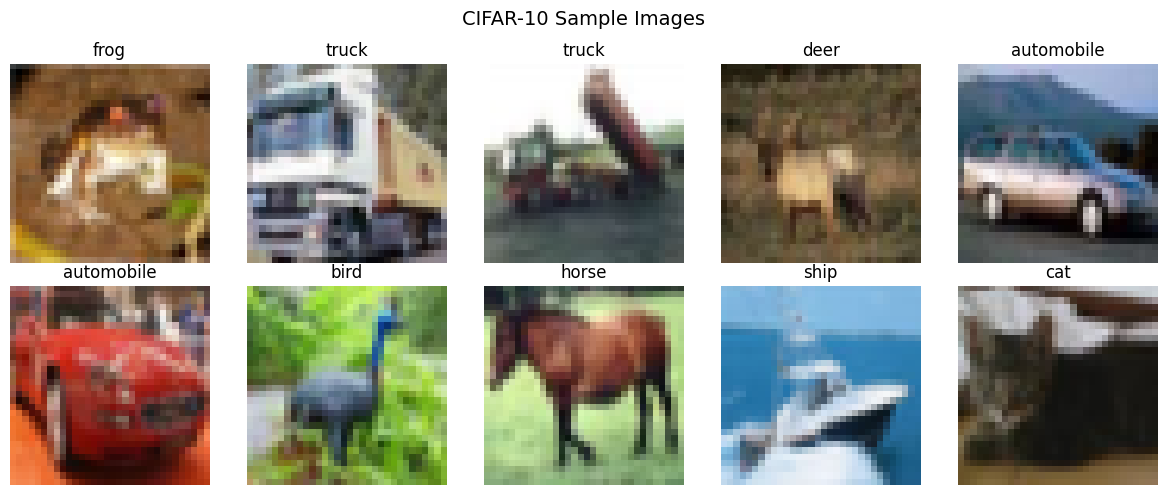

In [4]:
# Visualize sample images (provided)
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

viz_dataset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transforms.ToTensor())

for i, ax in enumerate(axes.flat):
    img, label = viz_dataset[i]
    ax.imshow(img.permute(1, 2, 0))
    ax.set_title(CLASS_NAMES[label])
    ax.axis('off')
plt.suptitle('CIFAR-10 Sample Images', fontsize=14)
plt.tight_layout()
plt.show()

## Part 2: Efficient CNN Architecture (<1M Parameters) (20 points)

Design a CNN with **less than 1 million parameters** that achieves good accuracy on CIFAR-10.

In [5]:
class EfficientCNN(nn.Module):
    """
    An efficient CNN for CIFAR-10 with less than 1M parameters.

    Requirements:
        - Total parameters < 1,000,000
        - Must use convolutional layers
        - Must achieve reasonable accuracy (aim for >80%)
    """

    def __init__(self, num_classes=10):
        super(EfficientCNN, self).__init__()

        # TODO: Design your efficient CNN architecture
        self.features = nn.Sequential(
            # 32x32
            nn.Conv2d(3, 64, 3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            nn.Conv2d(64, 64, 3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),  # 16x16

            nn.Conv2d(64, 96, 3, padding=1, bias=False),
            nn.BatchNorm2d(96),
            nn.ReLU(inplace=True),

            nn.Conv2d(96, 96, 3, padding=1, bias=False),
            nn.BatchNorm2d(96),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),  # 8x8

            nn.Conv2d(96, 128, 3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, 3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),  # 4x4
            nn.Conv2d(128, 192, 3, padding=1, bias=False),
            nn.BatchNorm2d(192),
            nn.ReLU(inplace=True),
            nn.Dropout(0.2),
            nn.Conv2d(192, 192, 3, padding=1, bias=False),
            nn.BatchNorm2d(192),
            nn.ReLU(inplace=True),
        )

        # global avg pool -> small classifier
        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Linear(192, num_classes)

       # raise NotImplementedError()

    def forward(self, x):
        """
        Forward pass.

        Args:
            x: Input tensor of shape (batch_size, 3, 32, 32)

        Returns:
            Output tensor of shape (batch_size, num_classes)
        """
        # TODO: Implement forward pass
        x = self.features(x)
        x = self.gap(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x
        #raise NotImplementedError()

In [6]:
def count_parameters(model):
    """Count total trainable parameters."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# Verify architecture
model = EfficientCNN(num_classes=NUM_CLASSES).to(device)
print(model)

# Test forward pass
dummy_input = torch.randn(2, 3, 32, 32).to(device)
dummy_output = model(dummy_input)

# Verify constraints
num_params = count_parameters(model)
print(f"\n✓ Input shape: {dummy_input.shape}")
print(f"✓ Output shape: {dummy_output.shape}")
print(f"\nTotal parameters: {num_params:,}")

if num_params < 1_000_000:
    print("✓ Parameter constraint satisfied (<1M)")
else:
    print(f"✗ Too many parameters! Need to reduce by {num_params - 1_000_000:,}")

EfficientCNN(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(64, 96, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (8): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (9): ReLU(inplace=True)
    (10): Conv2d(96, 96, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (11): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (12): ReLU(inplace=True)
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, di

## Part 3: Training (15 points)

Implement the training and evaluation functions.

In [7]:
def train_epoch(model, train_loader, criterion, optimizer, device):
    """
    Train for one epoch.

    Args:
        model: The CNN model
        train_loader: DataLoader for training data
        criterion: Loss function
        optimizer: Optimizer
        device: cuda or cpu

    Returns:
        avg_loss: Average loss over all batches
        accuracy: Training accuracy (percentage)
    """
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(train_loader, desc='Training', leave=False):
        images, labels = images.to(device), labels.to(device)

        # TODO: Implement training step
        # 1. Zero gradients

        optimizer.zero_grad()
        # 2. Forward pass
        outputs = model(images)
        # 3. Compute loss
        loss = criterion(outputs, labels)
        # 4. Backward pass
        loss.backward()
        # 5. Update weights
        optimizer.step()
        # 6. Update running_loss, correct, total
        running_loss += loss.item()
        _, preds = outputs.max(1)
        total += labels.size(0)
        correct += (preds == labels).sum().item()

        #raise NotImplementedError()

    return running_loss / len(train_loader), 100. * correct / total


def evaluate(model, test_loader, criterion, device):
    """
    Evaluate on test set.

    Args:
        model: The CNN model
        test_loader: DataLoader for test data
        criterion: Loss function
        device: cuda or cpu

    Returns:
        avg_loss: Average test loss
        accuracy: Test accuracy (percentage)
    """
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in tqdm(test_loader, desc='Evaluating', leave=False):
            images, labels = images.to(device), labels.to(device)

            # TODO: Implement evaluation step
            outputs = model(images)
            loss = criterion(outputs, labels)
            running_loss += loss.item()
            _, preds = outputs.max(1)
            total += labels.size(0)
            correct += (preds == labels).sum().item()
            #raise NotImplementedError()

    return running_loss / len(test_loader), 100. * correct / total

In [8]:
def train_model(model, train_loader, test_loader, num_epochs, learning_rate, device):
    """Full training loop with Adam optimizer."""
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    history = {
        'train_loss': [], 'train_acc': [],
        'test_loss': [], 'test_acc': []
    }

    for epoch in range(num_epochs):
        start_time = time.time()

        train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
        test_loss, test_acc = evaluate(model, test_loader, criterion, device)

        epoch_time = time.time() - start_time

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['test_loss'].append(test_loss)
        history['test_acc'].append(test_acc)

        print(f"Epoch [{epoch+1}/{num_epochs}] "
              f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}% | "
              f"Test Loss: {test_loss:.4f}, Test Acc: {test_acc:.2f}% | "
              f"Time: {epoch_time:.1f}s")

    return history

In [9]:
# Train the model
print("="*60)
print("Training Efficient CNN")
print("="*60)

model = EfficientCNN(num_classes=NUM_CLASSES).to(device)
history = train_model(
    model, train_loader, test_loader,
    num_epochs=NUM_EPOCHS, learning_rate=LEARNING_RATE, device=device
)

print(f"\nFinal Test Accuracy: {history['test_acc'][-1]:.2f}%")

Training Efficient CNN


Training:   0%|          | 0/391 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/79 [00:00<?, ?it/s]

Epoch [1/15] Train Loss: 1.2595, Train Acc: 53.83% | Test Loss: 1.2319, Test Acc: 57.83% | Time: 24.5s


Training:   0%|          | 0/391 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/79 [00:00<?, ?it/s]

... (36 outputs left out)

Epoch [14/15] Train Loss: 0.2757, Train Acc: 90.38% | Test Loss: 0.4327, Test Acc: 86.21% | Time: 23.7s


Training:   0%|          | 0/391 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/79 [00:00<?, ?it/s]

Epoch [15/15] Train Loss: 0.2624, Train Acc: 90.93% | Test Loss: 0.3827, Test Acc: 87.91% | Time: 23.6s

Final Test Accuracy: 87.91%


## Part 4: Visualizations (15 points)

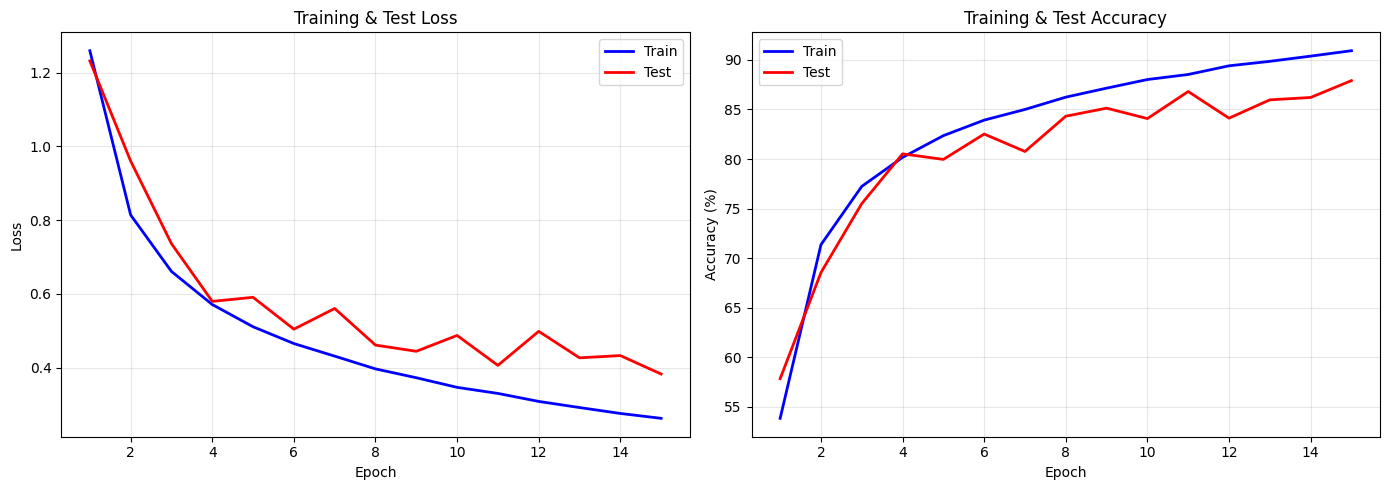

In [10]:
# Plot training curves (provided)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

epochs = range(1, NUM_EPOCHS + 1)

axes[0].plot(epochs, history['train_loss'], 'b-', label='Train', linewidth=2)
axes[0].plot(epochs, history['test_loss'], 'r-', label='Test', linewidth=2)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Training & Test Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs, history['train_acc'], 'b-', label='Train', linewidth=2)
axes[1].plot(epochs, history['test_acc'], 'r-', label='Test', linewidth=2)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].set_title('Training & Test Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [11]:
def get_predictions(model, data_loader, device):
    """Get all predictions and labels from a data loader."""
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            outputs = model(images)
            _, preds = outputs.max(1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())

    return np.array(all_preds), np.array(all_labels)

In [12]:
def plot_confusion_matrix(model, data_loader, device, class_names, title='Confusion Matrix'):
    """
    Plot confusion matrix for a model.
    """
    # TODO: Implement confusion matrix visualization
    # 1. Get predictions
    preds, labels = get_predictions(model, data_loader, device)
    # 2. Compute confusion matrix
    cm = confusion_matrix(labels, preds)
    # 3. Plot using seaborn heatmap
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('predicted')
    plt.ylabel('true')
    plt.title(title)
    #raise NotImplementedError()

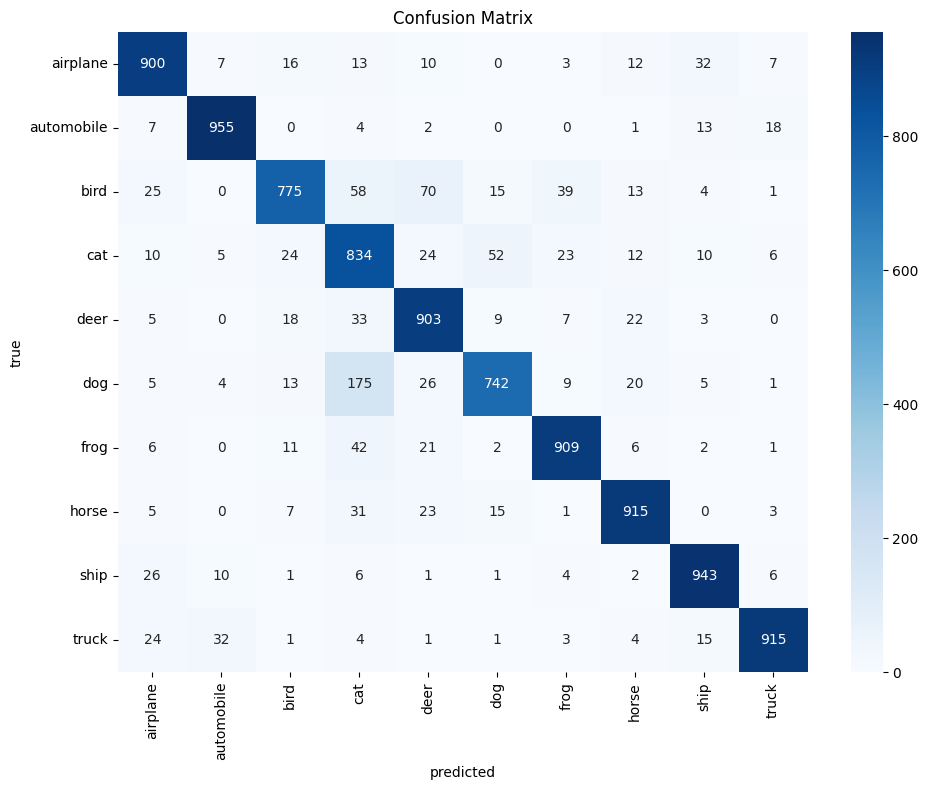

In [13]:
# Plot confusion matrix
plt.figure(figsize=(10, 8))
plot_confusion_matrix(model, test_loader, device, CLASS_NAMES)
plt.tight_layout()
plt.show()

In [16]:
def visualize_predictions(model, dataset, device, class_names, num_samples=10):
    """
    Visualize model predictions on sample images.
    """
    # TODO: Implement prediction visualization
    # Show images with true and predicted labels
    # Color correct predictions green, incorrect red
    model.eval()
    # use unnormalized images for display, but model needs normalized -> reuse dataset already normalized
    # so we denormalize for plotting here
    mean = torch.tensor([0.4914, 0.4822, 0.4465]).view(3, 1, 1)
    std  = torch.tensor([0.2470, 0.2435, 0.2616]).view(3, 1, 1)
    idxs = np.random.choice(len(dataset), num_samples, replace=False)
    cols = 5
    rows = (num_samples + cols - 1) // cols
    plt.figure(figsize=(3.2 * cols, 3.2 * rows))
    with torch.no_grad():
        for i, idx in enumerate(idxs):
            img, label = dataset[idx]
            x = img.unsqueeze(0).to(device)
            out = model(x)
            pred = out.argmax(dim=1).item()
            # denorm for display
            img_dn = img.cpu() * std + mean
            img_dn = torch.clamp(img_dn, 0, 1)
            img_dn = img_dn.permute(1, 2, 0).numpy()
            ok = (pred == label)
            #x = img.unsqueeze(0).to(device)
            title_color = 'green' if ok else 'red'
            plt.subplot(rows, cols, i + 1)
            plt.imshow(img_dn)
            plt.axis('off')
            plt.title(f"t:{class_names[label]}\np:{class_names[pred]}", color=title_color, fontsize=10)

    plt.tight_layout()
    plt.show()
    #raise NotImplementedError()

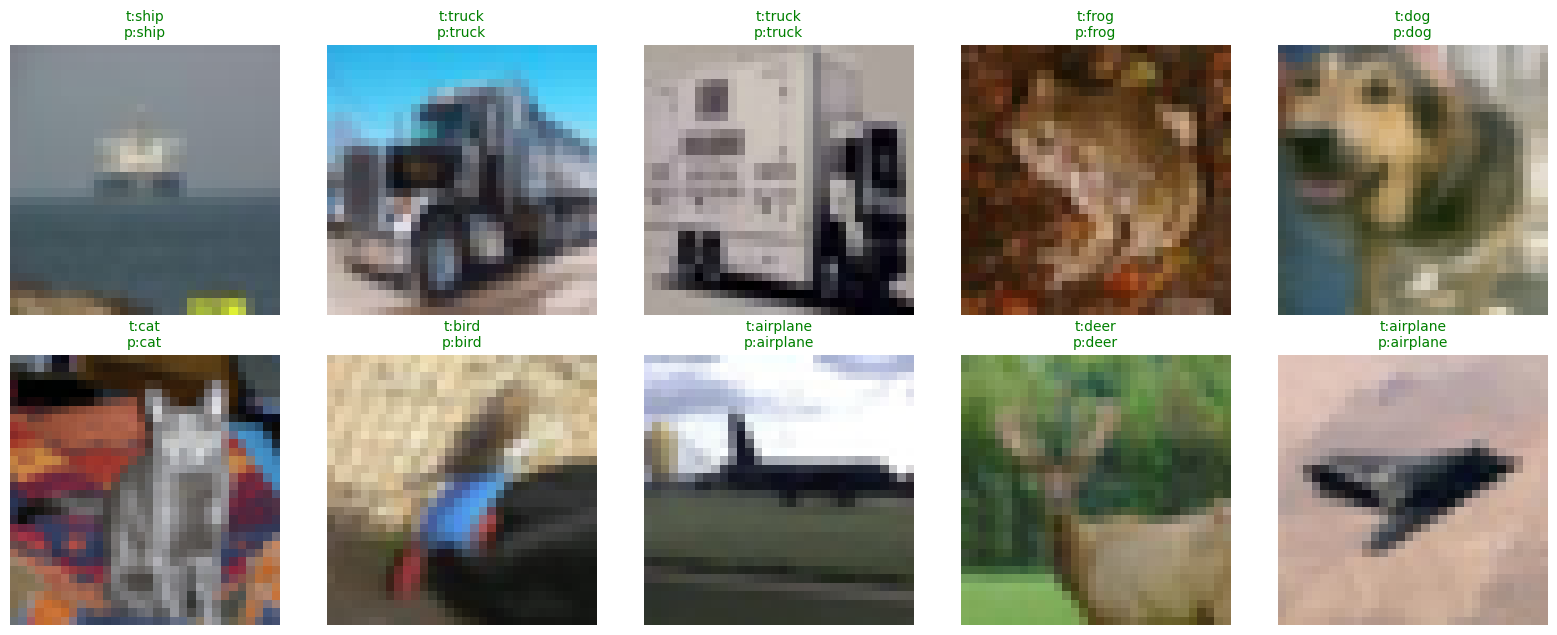

In [17]:
# Visualize predictions
visualize_predictions(model, test_dataset, device, CLASS_NAMES)

## Part 5: GradCAM Implementation (30 points)

Implement **Gradient-weighted Class Activation Mapping (GradCAM)** to visualize which regions of an image the CNN focuses on when making predictions.

**GradCAM Algorithm:**
1. Forward pass: Get activations from target layer using a **forward hook**
2. Backward pass: Get gradients flowing into target layer using a **backward hook**
3. Compute importance weights: Global average pool the gradients
4. Compute weighted combination: Sum (weights × activations)
5. Apply ReLU: Keep only positive contributions
6. Upsample to input size

**Key Concepts:**
- Forward hooks capture layer outputs during forward pass
- Backward hooks capture gradients during backward pass
- The heatmap shows which spatial regions contribute most to a class prediction

In [18]:
class GradCAM:
    """
    GradCAM implementation for CNN visualization (provided).

    Gradient-weighted Class Activation Mapping uses the gradients flowing into
    the final convolutional layer to produce a coarse localization map highlighting
    important regions in the image for prediction.

    Usage:
        gradcam = GradCAM(model, target_layer)
        cam, pred_class = gradcam.generate_cam(input_image)
        gradcam.remove_hooks()  # Clean up after use

    Args:
        model: The trained CNN model
        target_layer: The convolutional layer to compute GradCAM for
    """

    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer

        # Storage for activations and gradients
        self.activations = None
        self.gradients = None

        # Register hooks
        self.forward_hook = None
        self.backward_hook = None
        self._register_hooks()

    def _register_hooks(self):
        """Register forward and backward hooks on the target layer."""
        def forward_hook_fn(module, input, output):
            self.activations = output.detach()

        def backward_hook_fn(module, grad_input, grad_output):
            self.gradients = grad_output[0].detach()

        self.forward_hook = self.target_layer.register_forward_hook(forward_hook_fn)
        self.backward_hook = self.target_layer.register_full_backward_hook(backward_hook_fn)

    def remove_hooks(self):
        """Remove registered hooks."""
        if self.forward_hook is not None:
            self.forward_hook.remove()
        if self.backward_hook is not None:
            self.backward_hook.remove()

    def generate_cam(self, input_image, target_class=None):
        """
        Generate GradCAM heatmap for an input image.

        Args:
            input_image: Tensor of shape (1, C, H, W)
            target_class: Class index to compute CAM for (None = predicted class)

        Returns:
            cam: Normalized heatmap of shape (H, W) with values in [0, 1]
            pred_class: Predicted class index
        """
        self.model.eval()
        input_image.requires_grad = True

        # Forward pass (hooks capture activations)
        output = self.model(input_image)

        # Determine target class
        if target_class is None:
            pred_class = output.argmax(dim=1).item()
        else:
            pred_class = target_class

        # Backward pass to get gradients
        self.model.zero_grad()
        one_hot = torch.zeros_like(output)
        one_hot[0, pred_class] = 1.0
        output.backward(gradient=one_hot, retain_graph=False)

        # Compute importance weights (global average pooling of gradients)
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)  # (1, C, 1, 1)

        # Weighted combination of activations
        cam = (weights * self.activations).sum(dim=1, keepdim=True)  # (1, 1, H, W)

        # Apply ReLU and normalize
        cam = F.relu(cam)
        cam = cam.squeeze()  # (H, W)

        if cam.max() > 0:
            cam = (cam - cam.min()) / (cam.max() - cam.min())

        # Resize to input image size
        cam = cam.unsqueeze(0).unsqueeze(0)  # (1, 1, H, W)
        cam = F.interpolate(cam, size=input_image.shape[2:], mode='bilinear', align_corners=False)
        cam = cam.squeeze().cpu().numpy()  # (H, W)

        return cam, pred_class

In [19]:
# Test GradCAM implementation
print("Testing GradCAM implementation...")

# Get a test image
test_img, test_label = test_dataset[0]
test_img_batch = test_img.unsqueeze(0).to(device)

# Create GradCAM for the last conv layer (you may need to adjust based on your architecture)
# Find the last convolutional layer in your model
target_layer = None
for name, module in model.named_modules():
    if isinstance(module, nn.Conv2d):
        target_layer = module
        target_layer_name = name

print(f"Using layer: {target_layer_name}")

gradcam = GradCAM(model, target_layer)
cam, pred_class = gradcam.generate_cam(test_img_batch)

print(f"\n✓ CAM shape: {cam.shape}")
print(f"✓ Predicted class: {CLASS_NAMES[pred_class]}")
print(f"✓ True class: {CLASS_NAMES[test_label]}")

gradcam.remove_hooks()

Testing GradCAM implementation...
Using layer: features.25

✓ CAM shape: (32, 32)
✓ Predicted class: cat
✓ True class: cat


## Part 6: GradCAM Visualization (10 points)

Visualize GradCAM heatmaps overlaid on input images.

In [20]:
def visualize_gradcam(model, target_layer, image, label, class_names, device):
    """
    Visualize GradCAM for a single image.

    Shows three subplots side-by-side:
    1. Original image (denormalized)
    2. GradCAM heatmap
    3. Overlay of heatmap on original image

    Args:
        model: Trained model
        target_layer: Layer to compute GradCAM for
        image: Normalized input tensor (C, H, W)
        label: True label
        class_names: List of class names
        device: cuda or cpu
    """
    # TODO: Implement GradCAM visualization
    mean = torch.tensor([0.4914, 0.4822, 0.4465]).view(3, 1, 1)
    std  = torch.tensor([0.2470, 0.2435, 0.2616]).view(3, 1, 1)
    # 1. Create GradCAM object and generate CAM
    gradcam = GradCAM(model, target_layer)
    img_batch = image.unsqueeze(0).to(device)
    cam, pred_class = gradcam.generate_cam(img_batch)
    # 2. Denormalize the image for display
    img_dn = image.cpu() * std + mean
    img_dn = torch.clamp(img_dn, 0, 1)
    img_np = img_dn.permute(1, 2, 0).numpy()  # HWC, 0-1
    # 3. Create figure with 3 subplots (1 row, 3 columns)
    plt.figure(figsize=(12, 4))
    # 4. Subplot 1: Show original image
    plt.subplot(1, 3, 1)
    plt.imshow(img_np)
    plt.axis('off')
    plt.title(f"original\ntrue:{class_names[label]}")
    # 5. Subplot 2: Show heatmap using plt.imshow with 'jet' colormap
    plt.subplot(1, 3, 2)
    plt.imshow(cam, cmap='jet')
    plt.axis('off')
    plt.title(f"gradcam\npred:{class_names[pred_class]}")
    # 6. Subplot 3: Show overlay (convert heatmap to RGB using cv2.applyColorMap, blend with original)
    heat = (cam * 255).astype(np.uint8)
    heat_color = cv2.applyColorMap(heat, cv2.COLORMAP_JET)      # BGR
    heat_color = cv2.cvtColor(heat_color, cv2.COLOR_BGR2RGB)    # RGB
    heat_color = heat_color.astype(np.float32) / 255.0
    overlay = 0.55 * img_np.astype(np.float32) + 0.45 * heat_color
    overlay = np.clip(overlay, 0, 1)
    plt.subplot(1, 3, 3)
    plt.imshow(overlay)
    plt.axis('off')
    plt.title("overlay")
    plt.tight_layout()
    plt.show()
    # 8. Don't forget to remove hooks!
    gradcam.remove_hooks()
    #raise NotImplementedError()

In [21]:
def visualize_gradcam_multiple_layers(model, image, label, class_names, device):
    """
    Visualize GradCAM across multiple convolutional layers.

    This helps understand what different layers focus on:
    - Early layers: Focus on edges and simple patterns
    - Middle layers: Focus on textures and parts
    - Late layers: Focus on complete objects

    Args:
        model: Trained model
        image: Normalized input tensor (C, H, W)
        label: True label
        class_names: List of class names
        device: cuda or cpu
    """
    # TODO: Implement multi-layer GradCAM visualization
    # 1. Find all Conv2d layers in the model using model.named_modules()
    conv_layers = []
    for name, module in model.named_modules():
        if isinstance(module, nn.Conv2d):
            conv_layers.append((name, module))
    # keep it readable: pick a few layers (early, mid, late-ish)
    if len(conv_layers) > 6:
        picks = [0, len(conv_layers)//3, 2*len(conv_layers)//3, len(conv_layers)-1]
        conv_layers = [conv_layers[i] for i in picks]
    mean = torch.tensor([0.4914, 0.4822, 0.4465]).view(3, 1, 1)
    std  = torch.tensor([0.2470, 0.2435, 0.2616]).view(3, 1, 1)
    img_dn = image.cpu() * std + mean
    img_dn = torch.clamp(img_dn, 0, 1)
    img_np = img_dn.permute(1, 2, 0).numpy()

    # 3. Create a grid of subplots showing GradCAM for each layer
    n = len(conv_layers)
    plt.figure(figsize=(4 * n, 4))
    # original first
    plt.subplot(1, n + 1, 1)
    plt.imshow(img_np)
    plt.axis('off')
    plt.title(f"original\ntrue:{class_names[label]}")
    img_batch = image.unsqueeze(0).to(device)
    for i, (layer_name, layer_mod) in enumerate(conv_layers, start=2):
        # 2. For each conv layer, create GradCAM object and generate CAM
        gradcam = GradCAM(model, layer_mod)
        cam, pred_class = gradcam.generate_cam(img_batch)
        # overlay for nicer view
        heat = (cam * 255).astype(np.uint8)
        heat_color = cv2.applyColorMap(heat, cv2.COLORMAP_JET)
        heat_color = cv2.cvtColor(heat_color, cv2.COLOR_BGR2RGB)
        heat_color = heat_color.astype(np.float32) / 255.0
        overlay = 0.55 * img_np.astype(np.float32) + 0.45 * heat_color
        overlay = np.clip(overlay, 0, 1)

        plt.subplot(1, n + 1, i)
        plt.imshow(overlay)
        plt.axis('off')
        # 4. Label each subplot with the layer name
        plt.title(f"{layer_name}\npred:{class_names[pred_class]}", fontsize=9)
        # 5. Remember to remove hooks after each GradCAM generation!
        gradcam.remove_hooks()
    plt.tight_layout()
    plt.show()

    #raise NotImplementedError()

GradCAM Visualizations

Image 6252: True label = bird


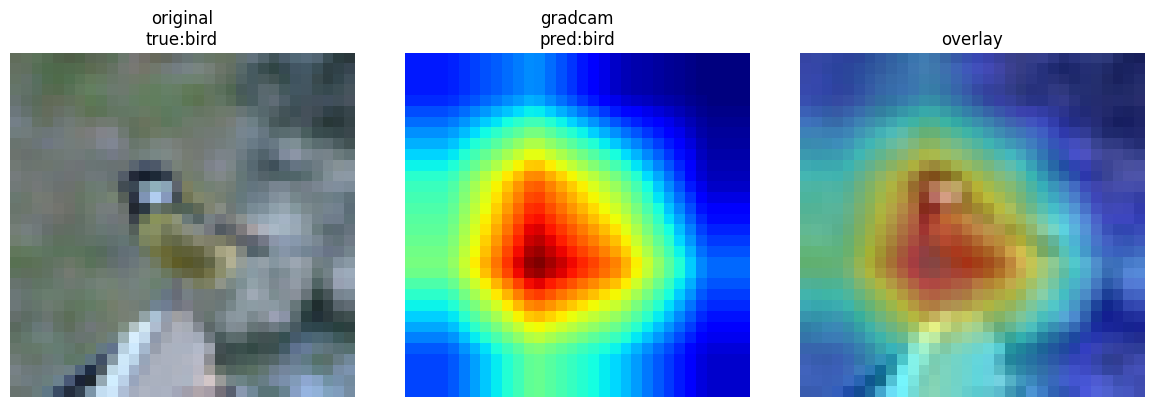


Image 4684: True label = automobile


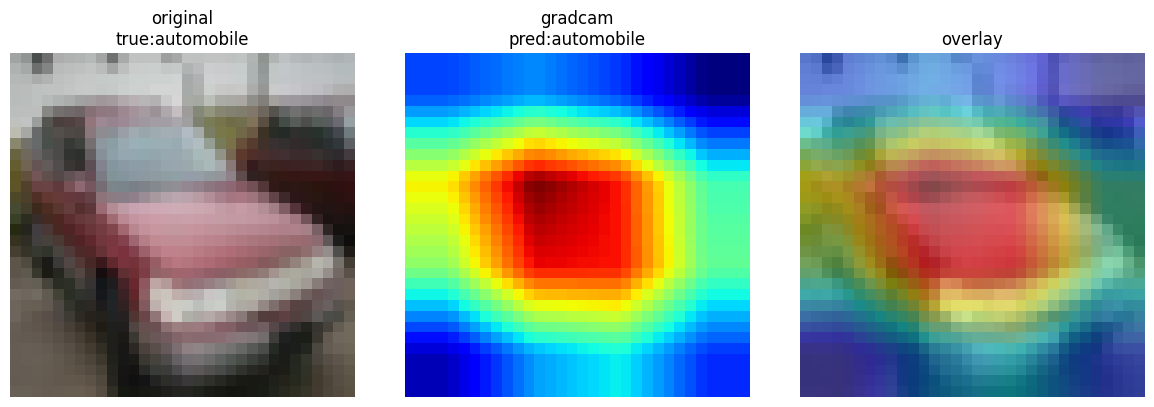


Image 1731: True label = dog


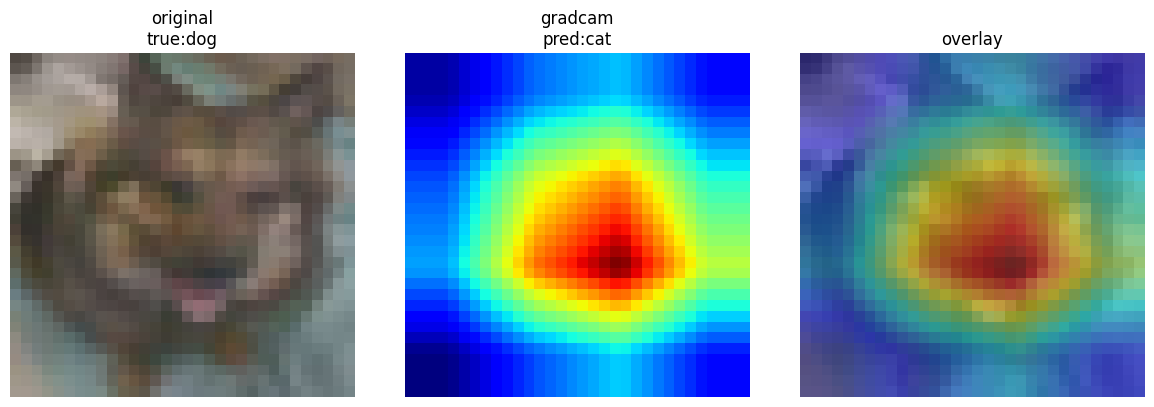


Image 4742: True label = ship


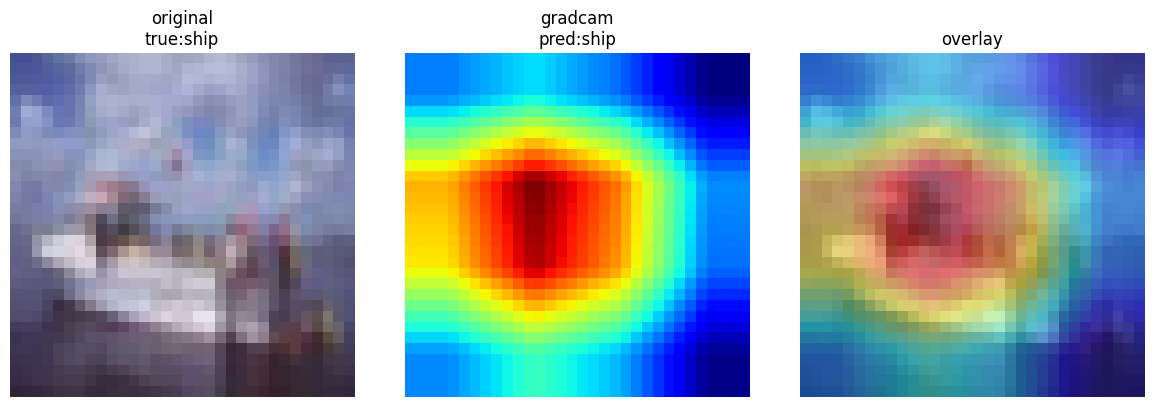


Image 4521: True label = truck


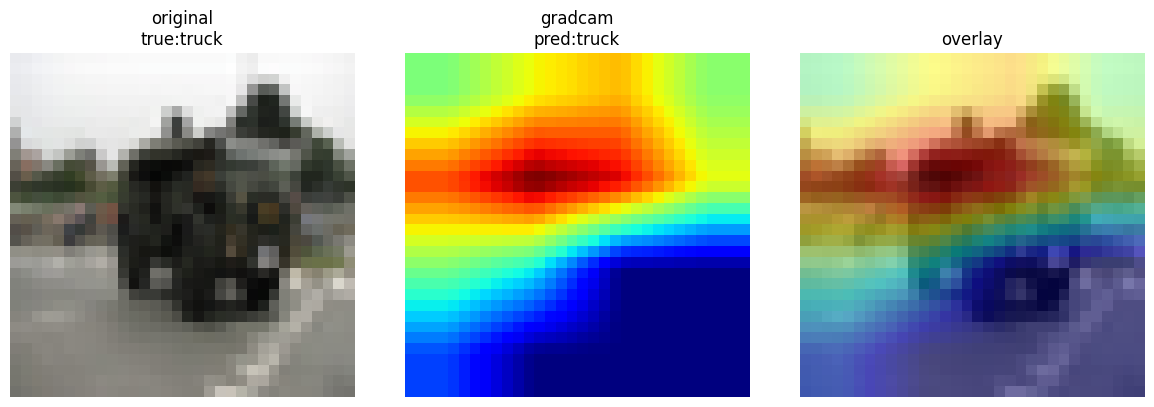

In [22]:
# Visualize GradCAM for sample images
print("GradCAM Visualizations")
print("="*50)

# Get unnormalized dataset for visualization
viz_dataset = torchvision.datasets.CIFAR10(
    root='./data', train=False, download=True,
    transform=transforms.ToTensor()
)

# Visualize for 5 random images
np.random.seed(42)
sample_indices = np.random.choice(len(test_dataset), 5, replace=False)

for idx in sample_indices:
    image, label = test_dataset[idx]
    print(f"\nImage {idx}: True label = {CLASS_NAMES[label]}")
    visualize_gradcam(model, target_layer, image, label, CLASS_NAMES, device)


GradCAM Across Different Layers


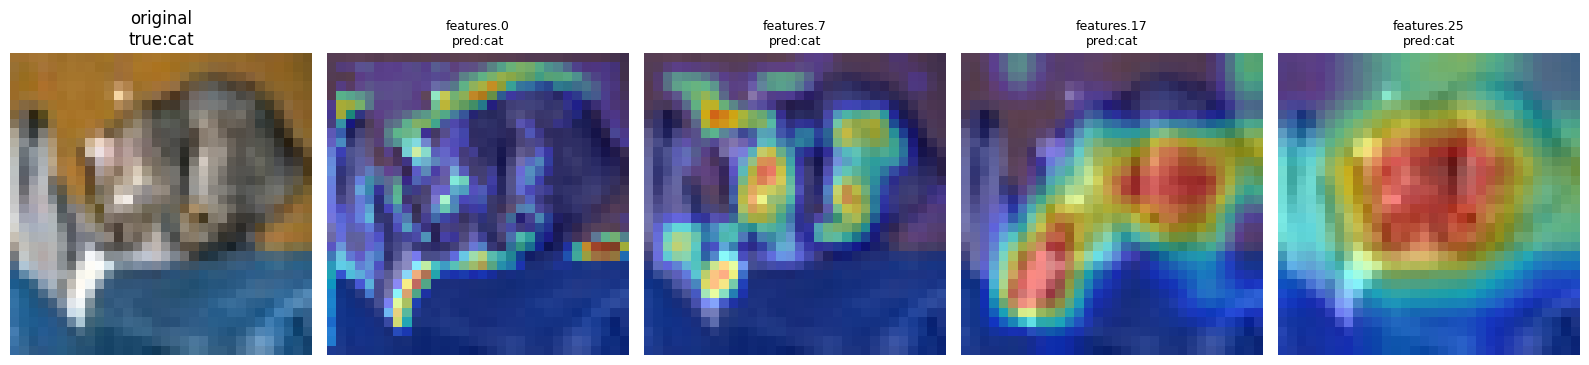

In [23]:
# Visualize GradCAM across different layers
print("\nGradCAM Across Different Layers")
print("="*50)

image, label = test_dataset[0]
visualize_gradcam_multiple_layers(model, image, label, CLASS_NAMES, device)

## Part 7: Analysis Questions (10 points)

In [24]:
# Summary (provided)
print("="*60)
print("MODEL SUMMARY")
print("="*60)
print(f"Total Parameters: {count_parameters(model):,}")
print(f"Final Test Accuracy: {history['test_acc'][-1]:.2f}%")
print(f"Best Test Accuracy: {max(history['test_acc']):.2f}%")

MODEL SUMMARY
Total Parameters: 991,690
Final Test Accuracy: 87.91%
Best Test Accuracy: 87.91%


### 📝 Analysis Questions

**Question 1:** Describe the architecture choices you made to keep parameters under 1M. What trade-offs did you consider?

**Question 2:** How do forward and backward hooks work in PyTorch? Why are they essential for GradCAM?

**Question 3:** Looking at the GradCAM visualizations across different layers, what patterns do you observe? How does the attention change from early to late layers?

**Question 4:** For which types of images does GradCAM produce meaningful attention maps? Are there cases where it fails?

**Your Answers:**

*[Double-click to edit this cell and write your answers here]*

**Answer 1:** to stay under 1m params, i focused on keeping the model “small but deep enough” instead of making it very wide.i used stacked 3x3 convolution blocks with moderate channel sizes, and downsampled using pooling so later layers work on smaller feature maps (this cuts compute and avoids needing huge channel counts). i also avoided large fully connected layers by using global avg pooling before the final classifier, so the classifier stays tiny and most capacity comes from convolutions. Batch normalization helped training stability, and dropout helped reduce overfitting. teh main trade off was capacity vs efficiency: fewer channels and no big dense layers keep parameters low and training fast, but if the network is too narrow it can miss fine-grained details in CIFAR-10 and accuracy drops.I balanced this by gradually increasing channels as resolution decreases, so later layers still have enough representational power


**Answer 2:** a forward hook is a small function you attach to a layer so that whenever the model runs a forward pass, you can “catch” that layer’s output (the activation feature maps) without rewriting the model.a backward hook is attached so that during backproop you can capture the gradients flowing back into that same layer. GradCAM needs both: it uses the forward activations to know what spatial features the layer produced, and it uses the backward gradients to know which channels were important for the chosen class. Without hooks, we would have to manually modify the network to return intermediate feature maps and gradients, which is messy.hooks let GradCAM read exactly what it needs while keeping the model unchanged


**Answer 3:** from my multi-layer GradCAM figure (the cat example), attention becomes more meaningful as i move deeper. nin the earliest layer view (features.0), the heatmap is more spread out and “texture or edge like” across large parts of the image, because early layers mostly detect simple patterns like edges and color contrasts.in the mid layer (features.7 and features.17), the attention starts concentrating around parts of the object (the cat region becomes clearer, with less focus on background). in the deepest layer shown (features.25), the heatmap is the most focused and object-centric, concentrating strongly on the main discriminative region (the cat’s face/body area).ths same pattern shows in my single-image GradCAM examples: for the bird and automobile, the strongest activation is centered on the actual object; for the ship, attention concentrates on the ship area rather than the sky; and for the dog image that was predicted as cat, the heatmap still targets the animal’s face region, showing the model is looking at the right place but confusing similar features


**Answer 4:** its s most meaningful when the image has one clear, fairly centered object with good contrast from the background. My bird, automobile, and ship examples are good cases: the heatmaps land on the object region and the overlay looks consistent with how a human would justify the prediction. It can struggle or look misleading when the object is small, blurry, partially occluded, or when two classes share very similar visual cues. My dog example (predicted cat) is a good failure style case: the attention is on the animals face, but that region contains features that could match both cat and dog in low-resolution CIFAR-10, so GradCAM looks “reasonable” even though the prediction is wrong. another failure mode is when the modal relies on background shortcuts (for example, sky/water cues for airplane vs ship, or grass/forest cues for deer/horse). in thse cases, GradCAM may highlight background areas instead of the object, which is a warning that the model might be using context more than the object itself.